# 02E - Going further: decay chains

**MATH 331 - Differential Equations.** Lecture plan: after Session 5 (a linear equation that is not homogeneous, solved with the integrating factor).

**This notebook is optional.** It goes beyond what the course asks, for those who want to see
the integrating factor of notebook 11 at work on a real problem.

**References**
* J. Lebl, *Notes on Diffy Qs*: Section 1.4 (linear equations and the integrating factor);
  Exercise 1.4.6 of the list at the end of the chapter (two lakes).
* W.A. Adkins and M.G. Davidson, *Ordinary Differential Equations* (Springer, 2012), Section 1.1
  (the law of decay).
* The solution for a chain of decays is known in physics as the *Bateman* solution.
* Related notebooks: 02 (decay and half-life), 11 (integrating factor), 13 (Exercise 4, the two
  lakes).

**What you will see**
1. A parent isotope that decays into a daughter, which decays in turn: two equations, solved
   one after the other.
2. A formula that divides by zero in one case, and what to do about it.
3. The daughter first grows, then follows the parent: *transient equilibrium*.
4. The same two equations in a problem with no physics in common: two lakes on a stream.

## 1. The chain

$N_P(t)$ atoms of the **parent** decay with constant $\lambda_P$. Each decay produces one atom of
the **daughter**, $N_D(t)$, which decays with constant $\lambda_D$ into something stable:

$$ \frac{dN_P}{dt} = -\lambda_P N_P, \qquad
\frac{dN_D}{dt} = \underbrace{\lambda_P N_P}_{\text{produced by the parent}} - \underbrace{\lambda_D N_D}_{\text{its own decay}} . $$

It is a balance, as in notebook 13: rate in minus rate out. The first equation does not contain
the daughter, so it can be solved first: $N_P = N_{P0}\,e^{-\lambda_P t}$ (notebook 02). Put into
the second, it leaves a **linear** equation for the daughter that is **not homogeneous**:

$$ N_D' + \lambda_D\,N_D = \lambda_P N_{P0}\,e^{-\lambda_P t} . $$

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: decay_constant).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import Math, display                 # noqa: F401  (not used in every notebook)
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


## 2. The integrating factor

The method of notebook 11, with $p = \lambda_D$:

1. Integrating factor: $r(t) = e^{\int \lambda_D\,dt} = e^{\lambda_D t}$.
2. Multiply: $\;\big(e^{\lambda_D t} N_D\big)' = \lambda_P N_{P0}\,e^{(\lambda_D - \lambda_P)\,t}$.
3. Integrate from 0 to $t$. Here two cases appear.

**If $\lambda_D \ne \lambda_P$:**

$$ N_D(t) = N_{D0}\,e^{-\lambda_D t} + \frac{\lambda_P N_{P0}}{\lambda_D - \lambda_P}\,\big(e^{-\lambda_P t} - e^{-\lambda_D t}\big) . $$

**If $\lambda_D = \lambda_P = \lambda$:** the right-hand side of step 2 is the constant
$\lambda N_{P0}$, and

$$ N_D(t) = \big(N_{D0} + \lambda N_{P0}\,t\big)\,e^{-\lambda t} . $$

The first formula **divides by zero** when the two constants are equal. Nothing is wrong with the
equation there: the theorem of notebook 11 guarantees a solution for any constants. It is the
*formula* that needs a second case, and the second case is the **limit** of the first as
$\lambda_D \to \lambda_P$. SymPy checks both statements.

**The maximum of the daughter** (starting from none): $N_D' = 0$ gives
$\;t_{max} = \dfrac{\ln(\lambda_D/\lambda_P)}{\lambda_D - \lambda_P}$, and $t_{max} = 1/\lambda$ in the
equal case.

In [2]:
t = sp.symbols("t", nonnegative=True)
rate_P, rate_D, N_P0, N_D0, rate = sp.symbols("lambda_P lambda_D N_P0 N_D0 lambda", positive=True)
N_D = sp.Function("N_D")

equation = sp.Eq(N_D(t).diff(t), rate_P * N_P0 * sp.exp(-rate_P * t) - rate_D * N_D(t))
by_sympy = sp.dsolve(equation, N_D(t), ics={N_D(0): N_D0}).rhs

by_hand = N_D0 * sp.exp(-rate_D * t) + rate_P * N_P0 / (rate_D - rate_P) * (sp.exp(-rate_P * t) - sp.exp(-rate_D * t))
print("the formula found by hand equals SymPy's:", sp.simplify(by_sympy - by_hand) == 0)

equal_case = sp.limit(by_hand.subs(rate_P, rate), rate_D, rate)          # the limit of equal constants
print("limit for equal constants:", sp.factor(equal_case))

assert sp.simplify(by_sympy - by_hand) == 0
assert sp.simplify(equal_case - (N_D0 + rate * N_P0 * t) * sp.exp(-rate * t)) == 0

the formula found by hand equals SymPy's: True


limit for equal constants: (N_D0 + N_P0*lambda*t)*exp(-lambda*t)


## 3. The picture

An example from medicine: molybdenum-99 (half-life about 66 hours) decays into technetium-99m
(half-life about 6 hours), the isotope most used in medical imaging. Hospitals receive
molybdenum "generators" and draw off the technetium that builds up inside. (In reality only
about 88 % of the molybdenum decays produce technetium-99m: multiply the source term by that
fraction.)

The function `daughter` is the formula of Section 2, with its two cases. The plot compares it
with a numerical solution of the two equations, which knows nothing of the formula.

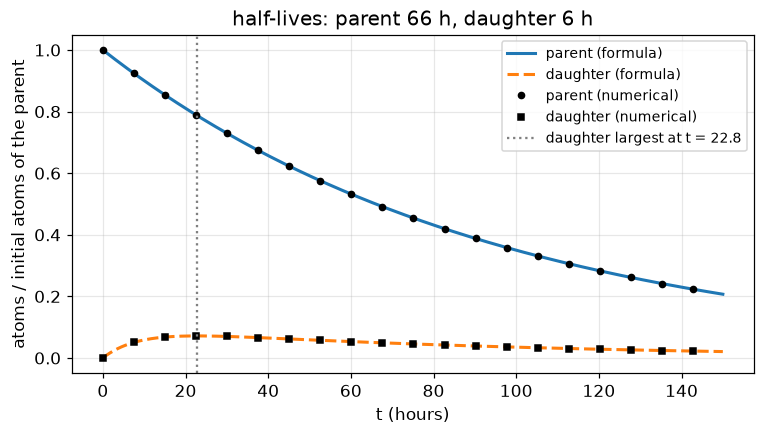

largest difference between formula and numerical solution (daughter): 2.7e-11


In [3]:
def daughter(t, N_P0, N_D0, lam_P, lam_D):
    # the daughter of Section 2, with the case of equal constants
    if np.isclose(lam_P, lam_D, rtol=1e-12, atol=0.0):
        return (N_D0 + lam_P * N_P0 * t) * np.exp(-lam_P * t)
    return (N_D0 * np.exp(-lam_D * t)
            + lam_P * N_P0 / (lam_D - lam_P) * (np.exp(-lam_P * t) - np.exp(-lam_D * t)))


def time_of_maximum(lam_P, lam_D):
    if np.isclose(lam_P, lam_D, rtol=1e-12, atol=0.0):
        return 1 / lam_P
    return np.log(lam_D / lam_P) / (lam_D - lam_P)


PARENT_HALF_LIFE, DAUGHTER_HALF_LIFE = 66.0, 6.0       # hours
HOURS = 150.0
WIDE_FIGURE = (8.0, 4.0)
N_POINTS = 500
DOT_EVERY = 25
TOLERANCE = 1e-10


def plot_chain(half_parent=PARENT_HALF_LIFE, half_daughter=DAUGHTER_HALF_LIFE, t_end=HOURS):
    # parent and daughter (as fractions of the initial parent): formula (lines) and numerical solution (dots)
    lam_P, lam_D = ol.decay_constant(half_parent), ol.decay_constant(half_daughter)
    times = np.linspace(0.0, t_end, N_POINTS)
    numerical = solve_ivp(lambda s, y: [-lam_P * y[0], lam_P * y[0] - lam_D * y[1]], (0.0, t_end), [1.0, 0.0],
                          rtol=TOLERANCE, atol=TOLERANCE, t_eval=times[::DOT_EVERY])
    t_max = time_of_maximum(lam_P, lam_D)
    fig, ax = plt.subplots(figsize=WIDE_FIGURE)
    ax.plot(times, np.exp(-lam_P * times), "-", linewidth=2, label="parent (formula)")
    ax.plot(times, daughter(times, 1.0, 0.0, lam_P, lam_D), "--", linewidth=2, label="daughter (formula)")
    ax.plot(numerical.t, numerical.y[0], "o", color="black", markersize=4, label="parent (numerical)")
    ax.plot(numerical.t, numerical.y[1], "s", color="black", markersize=4, label="daughter (numerical)")
    ax.axvline(t_max, linestyle=":", color="gray", label=f"daughter largest at t = {t_max:.3g}")
    ax.set_xlabel("t (hours)")
    ax.set_ylabel("atoms / initial atoms of the parent")
    ax.set_title(f"half-lives: parent {half_parent:g} h, daughter {half_daughter:g} h")
    ax.legend(loc="upper right")
    plt.show()
    gap = np.max(np.abs(numerical.y[1] - daughter(numerical.t, 1.0, 0.0, lam_P, lam_D)))
    print(f"largest difference between formula and numerical solution (daughter): {gap:.1e}")


plot_chain()

lam_P, lam_D = ol.decay_constant(PARENT_HALF_LIFE), ol.decay_constant(DAUGHTER_HALF_LIFE)
assert np.isclose(time_of_maximum(lam_P, lam_D), 22.8, atol=0.05)

*The plot shows* two curves over 150 hours. The parent (solid) decays slowly from 1. The
daughter (dashed) starts from 0, rises quickly to its largest value, about 0.07, after 22.8 hours
(dotted vertical line), and then falls, soon settling to a fixed fraction of the parent. The round and
square dots (numerical solution) lie on the two curves.

**Transient equilibrium.** When the daughter is shorter-lived than the parent
($\lambda_D > \lambda_P$), after a while $e^{-\lambda_D t}$ is negligible and

$$ \frac{N_D(t)}{N_P(t)} \;\longrightarrow\; \frac{\lambda_P}{\lambda_D - \lambda_P} : $$

the daughter decays at the pace of the parent. For the pair above the ratio is exactly
$\tfrac{1}{10}$.

**Sliders.** Before moving them, predict the shape of the daughter's curve in three cases:

1. daughter much shorter-lived than the parent (the generator above);
2. equal half-lives (the case in which the first formula fails);
3. daughter longer-lived than the parent.

In [4]:
HALF_LIFE_RANGE = (1.0, 200.0, 1.0)             # minimum, maximum, step (hours)
TIME_RANGE = (10.0, 600.0, 10.0)

interact(plot_chain,
         half_parent=FloatSlider(value=PARENT_HALF_LIFE, min=HALF_LIFE_RANGE[0], max=HALF_LIFE_RANGE[1],
                                 step=HALF_LIFE_RANGE[2], description="parent", continuous_update=False),
         half_daughter=FloatSlider(value=DAUGHTER_HALF_LIFE, min=HALF_LIFE_RANGE[0], max=HALF_LIFE_RANGE[1],
                                   step=HALF_LIFE_RANGE[2], description="daughter", continuous_update=False),
         t_end=FloatSlider(value=HOURS, min=TIME_RANGE[0], max=TIME_RANGE[1], step=TIME_RANGE[2],
                           description="t max", continuous_update=False));

interactive(children=(FloatSlider(value=66.0, continuous_update=False, description='parent', max=200.0, min=1....

(1: a quick rise, then the daughter follows the parent down. 2: the same shape, with the
maximum at $t = 1/\lambda$: nothing special happens to the *solution*. 3: the daughter rises
while the parent disappears, then decays slowly on its own.)

In [5]:
ratio = daughter(10 * PARENT_HALF_LIFE, 1.0, 0.0, lam_P, lam_D) / np.exp(-lam_P * 10 * PARENT_HALF_LIFE)
print(f"daughter / parent after ten half-lives of the parent: {ratio:.4f}   formula: {lam_P / (lam_D - lam_P):.4f}")
assert np.isclose(ratio, lam_P / (lam_D - lam_P)) and np.isclose(ratio, 0.1)

daughter / parent after ten half-lives of the parent: 0.1000   formula: 0.1000


## 4. The same equations, with no atoms: two lakes

*Lebl, Exercise 1.4.6* (it is Exercise 4 of notebook 13). Two lakes are on a stream: clean water
flows into the first, the first flows into the second, 500 litres per hour everywhere. The first
lake holds 100 thousand litres, the second 200 thousand. A truck with 500 kg of a toxic
substance crashes into the first lake.

The balances, for the kilograms $x_1$ and $x_2$ in the two lakes:

$$ x_1' = -\frac{500}{100\,000}\,x_1, \qquad x_2' = \frac{500}{100\,000}\,x_1 - \frac{500}{200\,000}\,x_2 . $$

They are the equations of Section 1, with $\lambda_P = 0.005$ and $\lambda_D = 0.0025$ per hour:
the first lake is the parent, the second the daughter. So the function `daughter` answers the
question "when is the second lake worst?" without any new work.

In [6]:
FLOW = 500.0                                # litres per hour
FIRST_LAKE, SECOND_LAKE = 100_000.0, 200_000.0          # litres
SPILL = 500.0                               # kg
LIMIT = 0.001                               # kg per litre

lake_P, lake_D = FLOW / FIRST_LAKE, FLOW / SECOND_LAKE
worst = time_of_maximum(lake_P, lake_D)
below = np.log(SPILL / FIRST_LAKE / LIMIT) / lake_P       # the first lake: x1 / volume = limit

print(f"second lake worst after {worst:.0f} hours, with {daughter(worst, SPILL, 0.0, lake_P, lake_D):.0f} kg in it")
print(f"first lake below {LIMIT} kg per litre after {below:.0f} hours")
assert np.isclose(worst, 400 * np.log(2)) and np.isclose(below, 200 * np.log(5))

second lake worst after 277 hours, with 250 kg in it
first lake below 0.001 kg per litre after 322 hours


The second lake is worst after about 277 hours, when it holds 250 kg, half of the spill; the
first lake is below the limit after about 322 hours. Here the "daughter" is *longer*-lived than
the "parent" (case 3 of the sliders).

## 5. Problems

These are ordinary problems, without automatic checks.

1. Derive the formula of Section 2 yourself with the integrating factor, and verify it by
   putting it into the equation.
2. Compute $\lim_{t\to\infty} N_D(t)/N_P(t)$ when $\lambda_D > \lambda_P$. What happens to the ratio
   when $\lambda_D < \lambda_P$?
3. Explain why the case $\lambda_D = \lambda_P$ is not a difficulty for the *differential
   equation* (use the theorem for linear equations of notebook 11), only for the *formula*.
4. Show that the equal case is the limit of the general formula (write
   $\lambda_D = \lambda_P + \varepsilon$ and use $e^{-\varepsilon t} \approx 1 - \varepsilon t$).
5. Add a third lake of 50 thousand litres after the second. Write its balance and solve the three
   equations numerically. When is the third lake worst?

<details>
<summary>Final answers (after trying)</summary>

2. $\dfrac{\lambda_P}{\lambda_D - \lambda_P}$; for $\lambda_D < \lambda_P$ the ratio grows without
   bound: the parent disappears first.
3. The coefficients $\lambda_D$ and $\lambda_P N_{P0}e^{-\lambda_P t}$ are continuous for all $t$,
   whatever the constants: a unique solution exists for all $t$.
5. $x_3' = \tfrac{500}{200\,000}\,x_2 - \tfrac{500}{50\,000}\,x_3$; the third lake is worst after
   about 402 hours.

</details>